Análise de Agrupamento de Clientes utilizando K-means

# Clusterização de Clientes utilizando K-means

## 1. Introdução

Este trabalho tem como objetivo aplicar o algoritmo de aprendizado não supervisionado K-means em um conjunto de dados real, buscando identificar grupos de clientes com padrões de consumo semelhantes.

Para isso, será utilizado o dataset Wholesale Customers, disponibilizado pelo UCI Machine Learning Repository, que contém informações sobre os gastos anuais de clientes de um distribuidor atacadista em diferentes categorias de produtos.

A análise utilizará o método do cotovelo e o coeficiente de silhueta para auxiliar na escolha da quantidade de grupos, além de avaliar e interpretar os resultados encontrados.

In [ ]:
# Importando as bibliotecas necessárias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [ ]:
from google.colab import files

arquivo = files.upload()

df = pd.read_csv(next(iter(arquivo)))

df.head()

Saving Wholesale customers data.csv to Wholesale customers data.csv


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
atributos = pd.DataFrame({
    "atributo": ["Channel", "Region", "Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"],
    "descrição": ["Canal (1 = Horeca; 2 = Varejo)", "Região (1 = Lisboa, 2 = Porto, 3 = Outra)",
                  "Gasto anual com frescos", "Gasto anual com laticínios", "Gasto anual com mercearia",
                  "Gasto anual com congelados", "Gasto anual com detergentes e papel", "Gasto anual com frios/delicatessen"],
    "unidade": ["código", "código"] + ["m.u./ano"] * 6,
    "tipo": ["categórico", "categórico"] + ["numérico contínuo"] * 6,
    "usado em X?": ["não (rótulo)", "não (categórico)"] + ["sim"] * 6,
})
atributos

,atributo,descrição,unidade,tipo,usado em X?
0,Channel,Canal (1 = Horeca; 2 = Varejo),código,categórico,não (rótulo)
1,Region,"Região (1 = Lisboa, 2 = Porto, 3 = Outra)",código,categórico,não (categórico)
2,Fresh,Gasto anual com frescos,m.u./ano,numérico contínuo,sim
3,Milk,Gasto anual com laticínios,m.u./ano,numérico contínuo,sim
4,Grocery,Gasto anual com mercearia,m.u./ano,numérico contínuo,sim
5,Frozen,Gasto anual com congelados,m.u./ano,numérico contínuo,sim
6,Detergents_Paper,Gasto anual com detergentes e papel,m.u./ano,numérico contínuo,sim
7,Delicassen,Gasto anual com frios/delicatessen,m.u./ano,numérico contínuo,sim


In [ ]:
# Verificando a quantidade de linhas e colunas

print("Quantidade de registros:", df.shape[0])
print("Quantidade de atributos:", df.shape[1])

# Informações gerais
df.info()

Quantidade de registros: 440
Quantidade de atributos: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [ ]:
# Descrição estatística dos dados

df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000



Célula Markdown 3
2. Preparação dos dados
Nesta etapa serão selecionados os atributos que serão utilizados pelo K-means. As colunas Channel e Region serão excluídas da matriz X, pois o objetivo é agrupar os clientes considerando somente seus padrões de gastos.**texto em negrito**

In [ ]:
# Selecionando os atributos numéricos de gastos

colunas = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

X = df[colunas].copy()

# Visualizando a matriz X
X.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [ ]:
# Verificando as dimensões finais

n, d = X.shape

print("Quantidade de clientes (n):", n)
print("Quantidade de atributos (d):", d)

print("Dimensão da matriz X:", X.shape)

Quantidade de clientes (n): 440
Quantidade de atributos (d): 6
Dimensão da matriz X: (440, 6)


In [ ]:
# Verificando valores ausentes

print("Valores ausentes por coluna:")
print(X.isnull().sum())

print("\nTotal de valores ausentes:")
print(X.isnull().sum().sum())

Valores ausentes por coluna:
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Total de valores ausentes:
0


In [ ]:
# Verificando registros duplicados

print("Registros duplicados:", X.duplicated().sum())

Registros duplicados: 0


#Justificativa das exclusões
A coluna Channel foi removida de X porque é um rótulo (tipo de cliente: Horeca ou Varejo); o K-means não pode usar a resposta. Ela será guardada apenas para comparar com os grupos depois do agrupamento. A coluna Region foi excluída por ser categórica nominal: os valores 1, 2 e 3 são apenas códigos, e ela descreve onde o cliente está, não como ele compra. O agrupamento usa somente os seis atributos de gasto.

In [ ]:
# Criando o padronizador

scaler = StandardScaler()

# Aplicando a padronização
X_scaled = scaler.fit_transform(X)

# Transformando em DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=colunas
)

# Visualizando os dados
X_scaled.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [ ]:
print(X_scaled.mean().round(6)); print(X_scaled.std(ddof=0).round(6))

Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64
Fresh               1.0
Milk                1.0
Grocery             1.0
Frozen              1.0
Detergents_Paper    1.0
Delicassen          1.0
dtype: float64


Explicação da padronização
A padronização é necessária porque os atributos possuem escalas diferentes. O StandardScaler transforma os valores utilizando a média e o desvio padrão de cada coluna.

Onde:
- x representa o valor original.
- μ representa a média.
- σ representa o desvio padrão.
- z representa o valor padronizado.

In [ ]:
# Comparando os valores originais e padronizados

comparacao = pd.DataFrame({
    "Valor original": X["Fresh"],
    "Valor padronizado": X_scaled["Fresh"]
})

comparacao.head(10)

,Valor original,Valor padronizado
0,12669,0.052933
1,7057,-0.391302
2,6353,-0.447029
3,13265,0.100111
4,22615,0.840239
5,9413,-0.204806
6,12126,0.009950
7,7579,-0.349981
8,5963,-0.477901
9,6006,-0.474497


A comparação demonstra que os valores originais foram transformados pela padronização. Após esse processo, os dados passaram a ter média próxima de zero e desvio padrão próximo de um. Isso permite que os seis atributos tenham influência mais equilibrada no cálculo das distâncias realizado pelo K-means.

### Etapa 3 — Execução do algoritmo K-means

Nesta etapa, será aplicado o algoritmo K-means utilizando os dados padronizados anteriormente.

Serão testados valores de K entre 1 e 10, representando diferentes quantidades de grupos. Para melhorar a qualidade dos resultados, será utilizada a inicialização `k-means++`, com 10 inicializações para cada valor de K.

O objetivo é observar como os dados são agrupados e registrar o valor de inércia (J) de cada execução.

In [ ]:
# Lista para guardar os resultados
resultados_kmeans = []

# Testar valores de K de 1 até 10
for k in range(1, 11):

    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    # Treinar o modelo
    modelo.fit(X_scaled)

    # Guardar o valor de inércia
    resultados_kmeans.append({
        "K": k,
        "Inercia (J)": modelo.inertia_
    })

# Mostrar os resultados
tabela_kmeans = pd.DataFrame(resultados_kmeans)

tabela_kmeans

,K,Inercia (J)
0,1,2640.000000
1,2,1954.647761
2,3,1608.431149
3,4,1317.838361
4,5,1058.771253
5,6,915.741260
6,7,822.722496
7,8,737.386203
8,9,661.449585
9,10,605.915109


### Análise inicial dos resultados

Após executar o algoritmo K-means para valores de K entre 1 e 10, observou-se que a inércia diminuiu progressivamente conforme aumentou a quantidade de grupos.

Esse comportamento é esperado, pois uma quantidade maior de grupos permite que os clientes sejam distribuídos em conjuntos menores e mais próximos de seus respectivos centroides.

Entretanto, a menor inércia não significa necessariamente o melhor agrupamento. Por isso, serão utilizados também o método do cotovelo e o coeficiente de silhueta para auxiliar na escolha do número adequado de grupos.

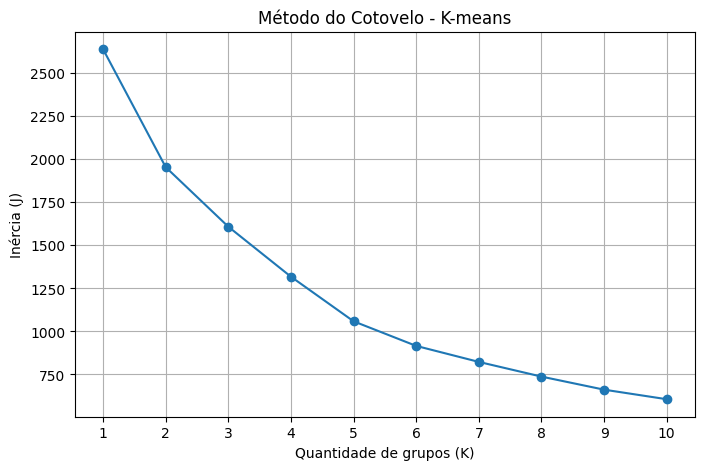

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    tabela_kmeans["K"],
    tabela_kmeans["Inercia (J)"],
    marker="o"
)

plt.title("Método do Cotovelo - K-means")
plt.xlabel("Quantidade de grupos (K)")
plt.ylabel("Inércia (J)")
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

### Análise do coeficiente de silhueta (Silhouette Score)

Nesta etapa, será calculado o coeficiente de silhueta para valores de K entre 2 e 10.

Esse indicador avalia a qualidade dos agrupamentos, considerando a proximidade dos clientes dentro do próprio grupo e a distância em relação aos outros grupos.

Quanto mais próximo de 1 for o resultado, melhor tende a ser a separação entre os grupos.

In [ ]:
# Lista para armazenar os resultados
resultados_silhouette = []

# Testar K de 2 até 10
for k in range(2, 11):

    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    # Treinar o modelo
    labels = modelo.fit_predict(X_scaled)

    # Calcular o Silhouette Score
    score = silhouette_score(X_scaled, labels)

    resultados_silhouette.append({
        "K": k,
        "Silhouette Score": score
    })

# Mostrar tabela
tabela_silhouette = pd.DataFrame(resultados_silhouette)

tabela_silhouette

,K,Silhouette Score
0,2,0.613694
1,3,0.548287
2,4,0.348471
3,5,0.369040
4,6,0.378229
5,7,0.303489
6,8,0.320116
7,9,0.309028
8,10,0.311214


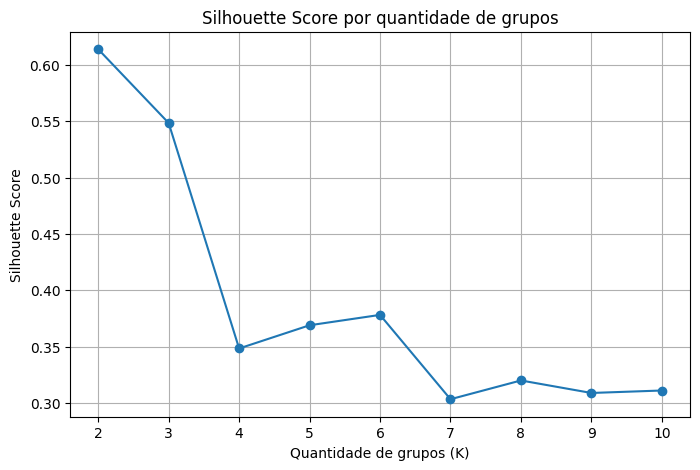

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    tabela_silhouette["K"],
    tabela_silhouette["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score por quantidade de grupos")
plt.xlabel("Quantidade de grupos (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

### Análise dos gráficos de silhueta

Serão construídos gráficos de silhueta para K=2 e K=3, permitindo visualizar a distribuição dos clientes em cada grupo.

Essa análise ajuda a identificar a qualidade da separação, a distribuição dos clientes e possíveis observações que não se encaixam bem nos agrupamentos.

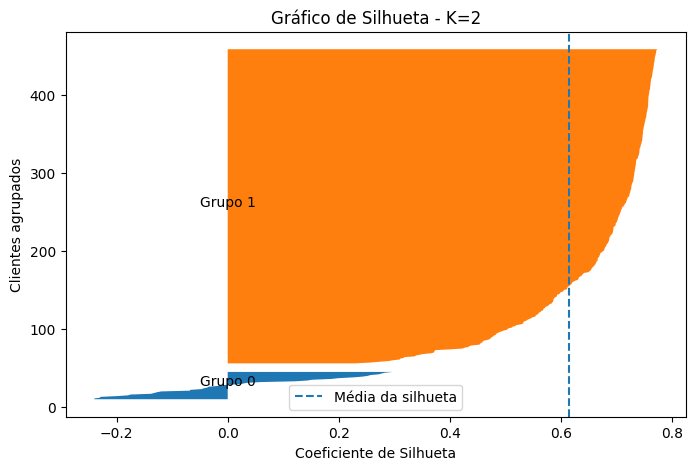

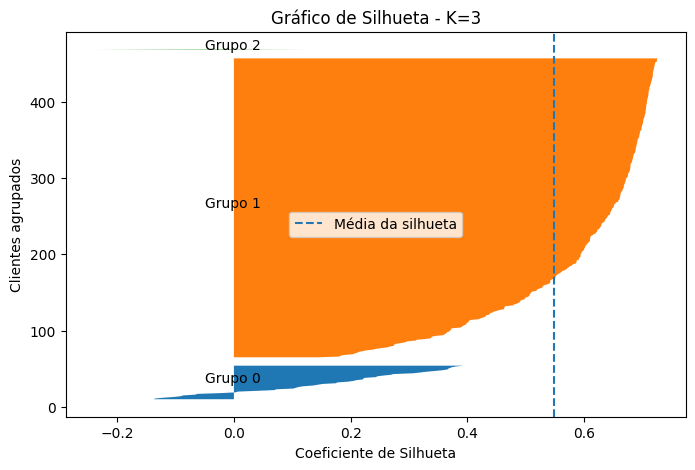

In [ ]:
from sklearn.metrics import silhouette_samples

# Analisar K=2 e K=3
for k in [2, 3]:

    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    labels = modelo.fit_predict(X_scaled)

    # Calcular silhueta individual
    valores_silhueta = silhouette_samples(X_scaled, labels)

    plt.figure(figsize=(8, 5))

    y_inicio = 10

    for i in range(k):

        valores_grupo = valores_silhueta[labels == i]
        valores_grupo.sort()

        tamanho = len(valores_grupo)
        y_fim = y_inicio + tamanho

        plt.fill_betweenx(
            np.arange(y_inicio, y_fim),
            0,
            valores_grupo
        )

        plt.text(-0.05, y_inicio + tamanho / 2, f"Grupo {i}")

        y_inicio = y_fim + 10

    plt.axvline(
        x=silhouette_score(X_scaled, labels),
        linestyle="--",
        label="Média da silhueta"
    )

    plt.title(f"Gráfico de Silhueta - K={k}")
    plt.xlabel("Coeficiente de Silhueta")
    plt.ylabel("Clientes agrupados")
    plt.legend()
    plt.show()

In [ ]:
for k in [2, 3]:
    modelo = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
    lab = modelo.fit_predict(X_scaled)
    s = silhouette_samples(X_scaled, lab)
    print(f"\nk={k} | J = {modelo.inertia_:.2f} | silhueta média = {s.mean():.3f} | pontos com s<0: {(s<0).sum()}")
    for g in range(k):
        print(f"  grupo {g}: n = {(lab==g).sum():3d} | silhueta média = {s[lab==g].mean():.2f}")


k=2 | J = 1954.65 | silhueta média = 0.614 | pontos com s<0: 19
  grupo 0: n =  36 | silhueta média = 0.02
  grupo 1: n = 404 | silhueta média = 0.67

k=3 | J = 1608.43 | silhueta média = 0.548 | pontos com s<0: 10
  grupo 0: n =  45 | silhueta média = 0.16
  grupo 1: n = 393 | silhueta média = 0.60
  grupo 2: n =   2 | silhueta média = -0.06


### Escolha da quantidade de grupos (K)

No método do cotovelo, a inércia vai caindo aos poucos, de 2640 (k=1) até 606 (k=10), e não dá pra ver um “cotovelo” claro. Só dá pra ver que a maior queda é entre k=1, 2 e 3.

Na silhueta, o maior valor foi com k=2 (0,614). Com k=3 deu 0,548, e de k=4 pra frente ficou entre 0,31 e 0,38. Então escolhi k=2.

Olhando o gráfico da silhueta, dá pra ver que o resultado não é tão bom quanto o número sugere. O grupo grande (404 clientes) está bem agrupado, mas o grupo pequeno (36 clientes) tem silhueta perto de 0 e 19 pontos negativos, ou seja, alguns clientes estão mal encaixados. Com k=3 apareceu um grupo com só 2 clientes, que não serve como grupo. Por isso k=2 foi a melhor opção, mas com essa ressalva.

### 5. Interpretação dos Grupos

Nesta etapa, vamos analisar as características de consumo dos dois grupos (clusters) encontrados para $K=2$.

Para isso, primeiro obteremos as etiquetas de cada cliente e a posição dos centroides. Em seguida, despadronizaremos os centroides para que voltem à escala monetária original (m.u./ano), permitindo uma interpretação direta dos gastos médios por categoria de produto.

In [ ]:
# Treinando o modelo final com K=2
modelo_final = KMeans(n_clusters=2, init='k-means++', n_init=20, random_state=42)
labels_final = modelo_final.fit_predict(X_scaled)

# Obtendo o tamanho de cada grupo
tamanho_grupo_0 = (labels_final == 0).sum()
tamanho_grupo_1 = (labels_final == 1).sum()

# Obtendo os centroides no espaço padronizado
centroides_scaled = modelo_final.cluster_centers_

# Desfazendo a padronização para voltar às unidades originais (m.u./ano)
centroides_originais = scaler.inverse_transform(centroides_scaled)

# Criando o DataFrame comparativo dos centroides
tabela_centroides = pd.DataFrame(
    centroides_originais,
    columns=colunas,
    index=['Centroide Grupo 0', 'Centroide Grupo 1']
)

# Adicionando o tamanho de cada grupo à tabela
tabela_centroides['Tamanho do Grupo (|C_k|)'] = [tamanho_grupo_0, tamanho_grupo_1]

# Exibindo os resultados
display(tabela_centroides.round(2))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Tamanho do Grupo (|C_k|)
Centroide Grupo 0,13556.19,21922.97,30602.89,4968.69,14516.33,4142.36,36
Centroide Grupo 1,11861.65,4359.23,5932.82,2902.91,1844.73,1291.63,404


#### Descrição e Perfis dos Grupos Gerados

Analisando a tabela de centroides nas unidades originais de gasto, podemos definir e nomear os dois grupos de clientes identificados:

* **Grupo 0 — Clientes de Alto Gasto / Atacadistas de Grande Porte (n = 36):**
  Este grupo representa uma pequena parcela de clientes ($8,18\%$ do total) que apresenta uma média de gastos extremamente alta em quase todas as categorias, especialmente em **Laticínios (Milk)**, **Mercearia (Grocery)** e **Detergentes/Papel**. São possivelmente distribuidores regionais, supermercados de rede ou grandes redes de hotéis e restaurantes com alto volume de compra.
  
* **Grupo 1 — Clientes de Gasto Moderado / Pequenos Comércios Locais (n = 404):**
  Este grupo abrange a grande maioria dos clientes ($91,82\%$ do total). O perfil de consumo é focado em gastos mais modestos e controlados. O principal destaque de consumo deles está em produtos **Frescos (Fresh)**, mantendo gastos muito baixos nas outras categorias. São caracterizados como pequenos restaurantes, padarias, hotéis familiares ou mercearias locais de bairro.

#### Visualização Gráfica em 2D dos Grupos

Como a matriz $X$ possui 6 dimensões, vamos escolher dois atributos de alto impacto para projetar e visualizar os clusters em um gráfico de dispersão de 2 dimensões. Usaremos os atributos `Grocery` (Mercearia) e `Fresh` (Frescos), plotados na escala de valores originais para facilitar a visualização do comportamento real dos clientes.

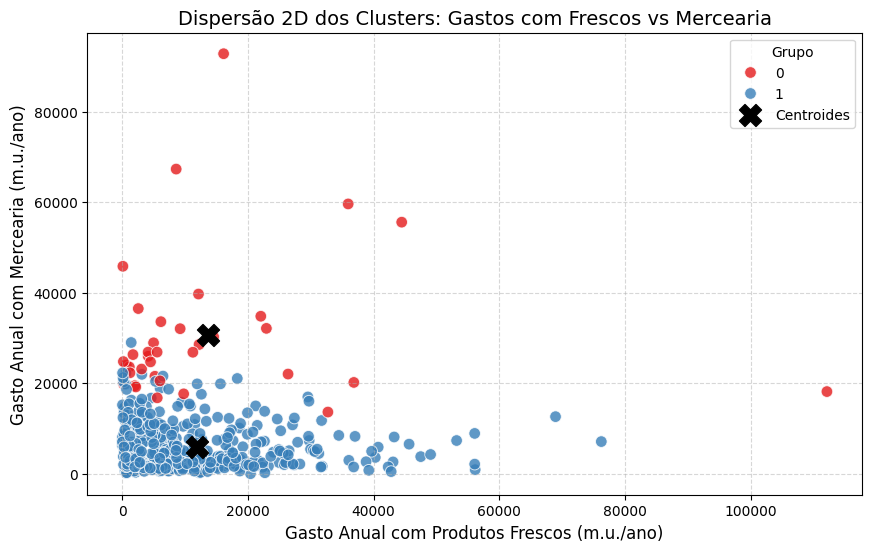

In [ ]:
plt.figure(figsize=(10, 6))

# Plotando os pontos e colorindo pelos clusters identificados
sns.scatterplot(
    x=X['Fresh'],
    y=X['Grocery'],
    hue=labels_final,
    palette='Set1',
    s=70,
    alpha=0.8
)

# Plotando os centroides originais
plt.scatter(
    centroides_originais[:, 0], # Fresh é o índice 0
    centroides_originais[:, 2], # Grocery é o índice 2
    color='black',
    marker='X',
    s=250,
    label='Centroides'
)

plt.title('Dispersão 2D dos Clusters: Gastos com Frescos vs Mercearia', fontsize=14)
plt.xlabel('Gasto Anual com Produtos Frescos (m.u./ano)', fontsize=12)
plt.ylabel('Gasto Anual com Mercearia (m.u./ano)', fontsize=12)
plt.legend(title='Grupo')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 6. Avaliação Crítica

Nesta última seção, avaliaremos a robustez do agrupamento por meio do cruzamento com o canal de vendas real e discutiremos as principais limitações do algoritmo aplicadas a este conjunto de dados.

#### Comparação com o Rótulo Real (`Channel`)

A coluna original `Channel` (que indica 1 = Horeca — Hotéis/Restaurantes/Cafés; 2 = Varejo) foi retirada antes de rodarmos o K-means para que o algoritmo agrupar de forma puramente não supervisionada.

Vamos agora criar uma matriz de confusão (cruzamento) para analisar se o K-means conseguiu reencontrar naturalmente esses canais originais através dos gastos.

In [ ]:
# Criando um DataFrame comparativo
comparativo_canais = pd.DataFrame({
    'Canal Real (Channel)': df['Channel'].map({1: '1 - Horeca', 2: '2 - Varejo'}),
    'Cluster K-means': labels_final
})

# Gerando tabela de contingência (matriz de cruzamento)
tabela_cruzamento = pd.crosstab(
    comparativo_canais['Canal Real (Channel)'],
    comparativo_canais['Cluster K-means']
)

display(tabela_cruzamento)

Cluster K-means,0,1
Canal Real (Channel),,
1 - Horeca,3,295
2 - Varejo,33,109


**Análise do Cruzamento:**

A comparação entre os grupos encontrados pelo K-means e os canais originais de venda demonstra que existe uma relação entre os padrões de consumo e o canal comercial, mas essa relação não é perfeita.

O Grupo 0 é composto predominantemente por clientes do Varejo, totalizando 33 clientes desse canal e apenas 3 clientes Horeca. Portanto, aproximadamente 91,67% desse grupo pertence ao Varejo.

Já o Grupo 1 contém 295 clientes Horeca e 109 clientes do Varejo. Isso demonstra que o agrupamento reuniu a maior parte dos clientes dos dois canais em um mesmo grupo de menor gasto relativo.

Esses resultados indicam que o K-means identificou principalmente diferenças nos volumes e padrões de gastos, mas não conseguiu separar completamente os clientes de acordo com seus canais comerciais originais.

#### Discussão de Limitações do Modelo

Apesar de termos encontrado um agrupamento coerente sob a ótica das métricas gerais, o modelo K-means apresenta limitações claras neste conjunto de dados:

1. **Sensibilidade a Outliers:**
   O dataset do Wholesale Customers é extremamente assimétrico e possui outliers de altíssimo valor (clientes que gastam muito acima da média). Como o K-means tenta minimizar a soma dos erros quadráticos (Inércia), esses poucos clientes puxam os centroides intensamente para si. Isso ficou claro na análise de $K=3$ gerando um grupo com apenas 2 clientes (outliers gigantes), reduzindo a utilidade prática de criar um terceiro perfil comercial.
   
2. **Suposição de Grupos Esféricos:**
   O K-means trabalha calculando a distância euclidiana, o que pressupõe que os agrupamentos possuem formato esférico de densidades e volumes semelhantes. No gráfico de dispersão gerado, nota-se que o Grupo 1 tem uma distribuição alongada e muito mais densa, enquanto o Grupo 0 é esparso e espalhado, violando a premissa de simetria geométrica ideal do algoritmo, justificando a presença de pontos com silhueta negativa.